# 04 — The official register, and what rents did

Two official sources next to the Airbnb data:

- **Barcelona's register of tourist flats (HUT)** — Ajuntament open data,
  quarterly. It is the legal count of licences, which Airbnb listings are not.
- **Average rent of new leases** — Generalitat de Catalunya (Incasòl
  deposits), quarterly, Barcelona as a whole.

**Privacy:** the register lists each flat down to floor and door. This
notebook only ever shows counts; `src/official.py` never returns addresses.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src import config as cfg
from src import cleaning, metrics, official
from src import sources as src

sns.set_theme(style="whitegrid", palette="colorblind")
LATEST_QUARTER = list(src.HUT_REGISTER_URLS)[-1]

snapshots = {date: cleaning.add_columns(cleaning.load_snapshot("barcelona", date))
             for date in src.SNAPSHOTS["barcelona"]}

## How many licences exist?

In [2]:
official.hut_totals().to_frame()

,registered_huts
2025_1T,10514
2025_2T,10569
2025_3T,10688
2025_4T,10723
2026_1T,10730
2026_3T,10721


About 10,700 licensed tourist flats, flat through 2025–2026. The register
does not shrink before the 2028 deadline of Decret llei 3/2023; this is the
number that deadline applies to.

## Do the licence numbers on Airbnb exist in the register?

Each listing's HUT number (regional section only — see
`cleaning.listing_hut_number`) is matched against the register's numbers.
Only counts are reported.

In [3]:
register = official.registered_hut_numbers(LATEST_QUARTER)

rows = []
for date, df in snapshots.items():
    shown = metrics.active(df)["license"].map(cleaning.listing_hut_number).dropna()
    distinct = set(shown)
    matched = distinct & register
    rows.append({
        "snapshot": date,
        "active_listings_with_hut": len(shown),
        "distinct_numbers": len(distinct),
        "match_register_pct": round(len(matched) / len(distinct) * 100, 1),
        "register_visible_on_airbnb_pct": round(len(matched) / len(register) * 100, 1),
        "numbers_on_2plus_listings": int((shown.value_counts() > 1).sum()),
    })
match = pd.DataFrame(rows).set_index("snapshot")
match

,active_listings_with_hut,distinct_numbers,match_register_pct,register_visible_on_airbnb_pct,numbers_on_2plus_listings
snapshot,,,,,
2025-12-14,5613,4711,83.4,37.0,427
2026-03-21,6357,5417,84.5,43.1,473
2026-06-24,7146,6116,84.7,48.8,524
2026-09-17,5330,4715,86.0,38.2,329


Three readings, each with its limit:

1. **~85% of displayed numbers match the register.** The rest can be typos,
   licences issued or cancelled between the two dates, or numbers that do
   not belong to the listing. The file cannot tell these apart, so the
   unmatched share is *not* a count of illegal listings.
2. **Only ~40–50% of registered flats appear on Airbnb at all.** The others
   may let through other platforms or directly — or not at all. Airbnb data
   alone understates the licensed market.
3. **A few hundred numbers appear on two or more listings.** One flat can be
   advertised more than once (for example with different minimum stays), so
   this is not evidence of a shared or borrowed licence by itself.

## Where are licences, and where are listings?

Per neighbourhood: registered flats (official) against active Airbnb
listings showing a tourist-flat licence.

In [4]:
latest = metrics.active(snapshots[src.SNAPSHOTS["barcelona"][-1]])
key = latest["neighbourhood"].map(official.normalise_place_name)

by_place = pd.DataFrame({
    "district": latest.groupby(key)["neighbourhood_group"].first(),
    "active_listings": latest.groupby(key)["id"].count(),
    "listings_with_licence": latest.groupby(key)["has_tourist_licence"].sum(),
}).join(official.hut_counts_by_neighbourhood(LATEST_QUARTER), how="outer").fillna(
    {"active_listings": 0, "listings_with_licence": 0, "registered_huts": 0})

rho, p_value = stats.spearmanr(by_place["registered_huts"], by_place["listings_with_licence"])
print(f"{len(by_place)} neighbourhoods, Spearman rho = {rho:.2f} (p = {p_value:.1e})")
by_place.sort_values("registered_huts", ascending=False).head(10)

70 neighbourhoods, Spearman rho = 0.97 (p = 9.9e-43)


,district,active_listings,listings_with_licence,registered_huts
neighbourhood,,,,
la dreta de l'eixample,Eixample,1658.0,792.0,1786.0
la sagrada família,Eixample,702.0,425.0,825.0
la vila de gràcia,Gràcia,719.0,361.0,805.0
l'antiga esquerra de l'eixample,Eixample,698.0,341.0,726.0
sant antoni,Eixample,600.0,346.0,669.0
el poble sec,Sants-Montjuïc,580.0,394.0,574.0
la nova esquerra de l'eixample,Eixample,457.0,243.0,510.0
el poblenou,Sant Martí,310.0,153.0,459.0
el fort pienc,Eixample,348.0,213.0,381.0


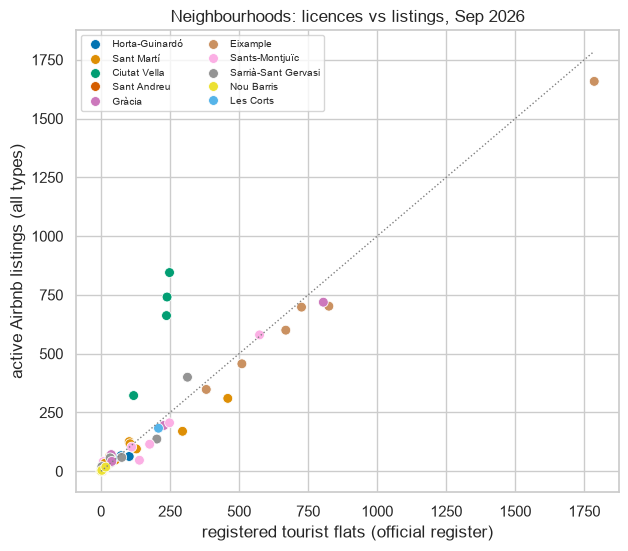

In [5]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=by_place, x="registered_huts", y="active_listings", hue="district", ax=ax, s=50)
top = by_place["registered_huts"].max()
ax.plot([0, top], [0, top], color="grey", ls=":", lw=1)
ax.set_xlabel("registered tourist flats (official register)")
ax.set_ylabel("active Airbnb listings (all types)")
ax.set_title("Neighbourhoods: licences vs listings, Sep 2026")
ax.legend(fontsize=7, ncol=2)
fig.savefig(cfg.FIGURES_DIR / "04_register_vs_listings.png", dpi=150, bbox_inches="tight")

Licences and listings sit in the same places (Spearman ρ close to 1).
Neighbourhoods **above** the dotted line have more active listings than
registered flats — almost all in Ciutat Vella. Two features of that district
explain much of it: over half of its active listings ask 31+ nights (54%, vs
32% in Eixample), and seasonal lets need no tourist licence; and a third are
private rooms, which cannot hold one.

In [6]:
for district in ["Ciutat Vella", "Eixample"]:
    d = latest[latest["neighbourhood_group"] == district]
    print(f"{district:13} active={len(d):,}  month-plus={(d['minimum_nights'] >= cfg.MAX_TOURIST_NIGHTS).mean():.0%}  "
          f"private rooms={(d['room_type'] == 'Private room').mean():.0%}  with licence={d['has_tourist_licence'].mean():.0%}")

Ciutat Vella  active=2,570  month-plus=54%  private rooms=32%  with licence=32%
Eixample      active=4,463  month-plus=32%  private rooms=24%  with licence=53%


## Rents of new leases, with the policy dates

**What this can show:** how the average rent of *new* leases moved. **What it
cannot show:** why. The average changes when the mix of flats rented
changes (size, area, quality), and many things move rents at once —
interest rates, wages, migration, supply. No causal claim is made.

,quarter_start,avg_rent,new_leases,year_on_year_pct
19,2023-10-01,1178.05,8531,9.3
20,2024-01-01,1193.51,9825,9.8
21,2024-04-01,1131.80,7938,0.7
22,2024-07-01,1133.33,7484,-3.2
23,2024-10-01,1117.39,7656,-5.1
24,2025-01-01,1087.23,7615,-8.9
25,2025-04-01,1135.55,7411,0.3
26,2025-07-01,1153.11,7855,1.7
27,2025-10-01,1160.99,7908,3.9
28,2026-01-01,1137.35,8156,4.6


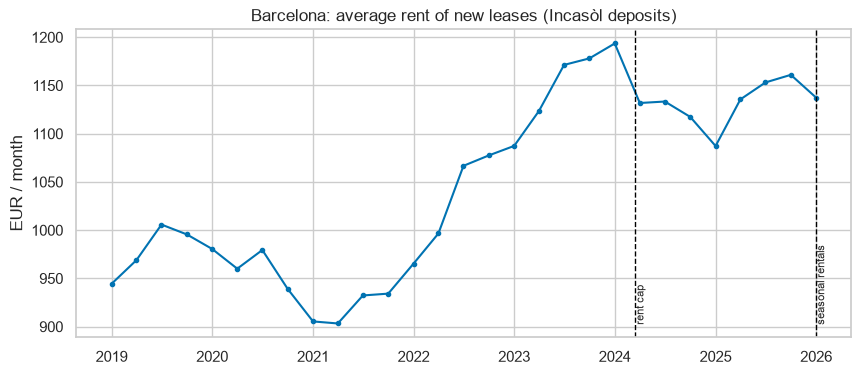

In [7]:
rents = official.load_rents()

fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.plot(rents["quarter_start"], rents["avg_rent"], marker="o", ms=3, label="average rent (EUR/month)")
ax1.set_ylabel("EUR / month")
for lever in ["rent_cap", "seasonal_rentals"]:
    date = pd.Timestamp(cfg.POLICY_LEVERS[lever]["applies_from"])
    ax1.axvline(date, color="black", ls="--", lw=1)
    ax1.text(date, ax1.get_ylim()[0] + 10, " " + lever.replace("_", " "), fontsize=8, rotation=90, va="bottom")
ax1.set_title("Barcelona: average rent of new leases (Incasòl deposits)")
fig.savefig(cfg.FIGURES_DIR / "04_rents.png", dpi=150, bbox_inches="tight")

rents.assign(year_on_year_pct=(rents["avg_rent"].pct_change(4) * 100).round(1)).tail(10)

## What I found

1. **The licence stock is flat.** ~10,700 registered tourist flats in every
   quarter from 2025 Q1 to 2026 Q3 (10,514 → 10,721). The 2028 deadline has
   not started to show.
2. **Most displayed licence numbers are real.** 83–86% of the HUT numbers on
   active listings match the official register. The rest cannot be
   classified from the data and are not counted as illegal.
3. **Airbnb shows less than half the licensed market.** Only 37–49% of
   registered flats appear on Airbnb with their number, depending on the
   snapshot.
4. **Licences and listings are in the same places** (Spearman ρ = 0.97 over
   70 neighbourhoods). Ciutat Vella is the exception, with more listings
   than licences: 54% of its active listings ask 31+ nights.
5. **Rents of new leases:** year-on-year growth went from about +10% in
   early 2024 to negative through Q1 2025 (−8.9%), then back to +4.6% in
   Q1 2026 (€1,137/month). The timing overlaps the rent cap, but the data
   cannot separate it from mix changes or the wider market.
